In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import model_selection, preprocessing


In [ ]:
def plot_hist(df):
     sns.set()

     plt.figure(figsize=(10, 6))
     for fold in df['kfold'].unique():
          fold_df = df[df['kfold'] == fold]
          plt.hist(fold_df['SalePrice'], alpha=0.6, label=f'Fold {fold}', bins=15)

     plt.xlabel('Target Value')
     plt.ylabel('Frequency')
     plt.title('Histogram of Target Variable within Each Fold')
     plt.legend()
     plt.show()


<Axes: >

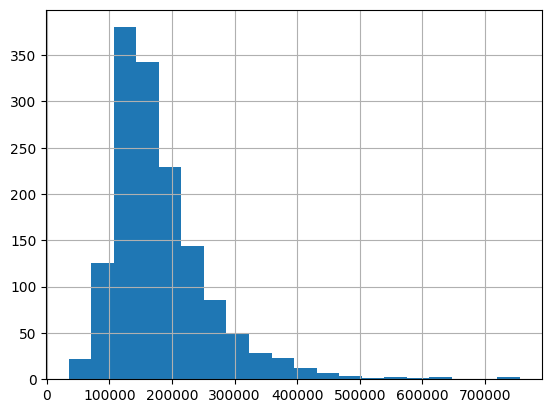

In [ ]:
trainset = pd.read_csv("../inputs/train.csv")
trainset['SalePrice'].hist(bins = 20)


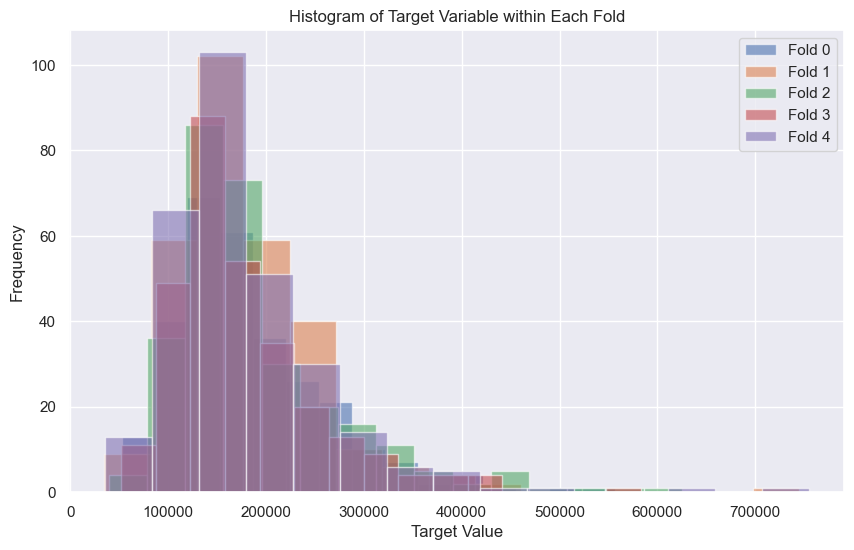

In [ ]:
train_folds = pd.read_csv("../inputs/train_folds.csv")
train_folds
plot_hist(train_folds)


In [ ]:
def check_collinearity(X, threshold=0.8):
    """
    Function to calculate the correlation matrix and flag collinearity
    among features in a dataset.
    
    Args:
    X (DataFrame): Feature dataset (numeric only).
    threshold (float): Correlation threshold to flag collinearity (default = 0.8).
    
    Returns:
    collinear_pairs (list): Pairs of features with correlation > threshold.
    """
    # Compute the correlation matrix
    corr_matrix = X.corr()

    # Find feature pairs with high correlation
    collinear_pairs = []
    for i in range(len(corr_matrix.columns)):
        for j in range(i + 1, len(corr_matrix.columns)):
            if abs(corr_matrix.iloc[i, j]) > threshold:
                collinear_pairs.append((corr_matrix.index[i], corr_matrix.columns[j], corr_matrix.iloc[i, j]))

    # Visualize correlation heatmap (optional)
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
    plt.title('Correlation Matrix')
    plt.show()

    return collinear_pairs

# Example usage
# X = Your feature DataFrame (ensure it's numeric)
high_corr_pairs = check_collinearity(pipe.fit_transform(X_train), threshold=0.65)
print("Highly collinear feature pairs:", high_corr_pairs)